# Exploration of Data using WGMS Data

Glaciers inside rough Karakoram boundary: 16801
Total inventory glacier area (km²): 23656.44


,region,outline_id,latitude,longitude,area_km2
100548,ASW,RGI60-14.07524,35.4284,76.893900,1077.958
99817,ASW,RGI60-14.06794,35.7416,76.404700,809.109
93028,ASW,RGI60-14.00005,36.0064,75.593200,559.807
97500,ASW,RGI60-14.04477,36.0550,75.281000,495.645
98913,ASW,RGI60-14.05890,35.2958,77.428400,439.616
...,...,...,...,...,...
185682,ASC,RGI60-13.39663,35.7820,78.443000,0.017
186052,ASC,RGI60-13.40033,36.1017,78.262299,0.017
186293,ASC,RGI60-13.40274,36.6670,77.774000,0.017
186181,ASC,RGI60-13.40162,36.4540,77.878000,0.014


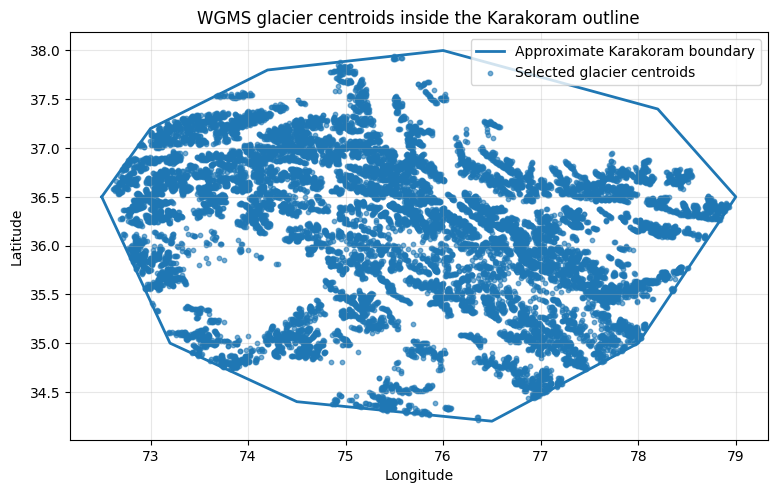

,area_weighted_mwe,mean_mwe,glaciers_with_data,area_with_data
year,,,,
1957,0.368619,0.394726,16801,23772.593
1958,0.848550,0.874724,16801,23772.593
1959,0.355815,0.380858,16801,23772.593
1960,0.417111,0.443371,16801,23772.593
1961,0.224388,0.249523,16801,23772.593
...,...,...,...,...
2021,-0.189361,-0.172486,16801,23772.593
2022,-0.778855,-0.748793,16801,23772.593
2023,-0.293474,-0.271400,16801,23772.593


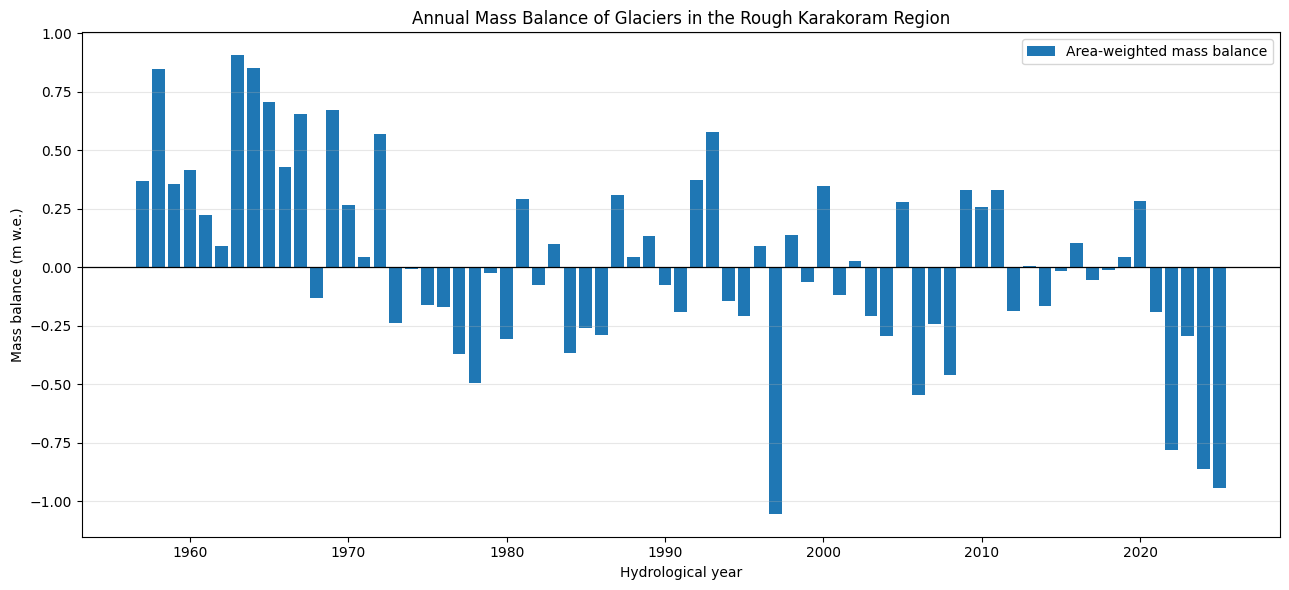

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import Point, Polygon

folder = Path("wgms-amce-2026-02-10/glacier")

# 1. Rough Karakoram outline: (longitude, latitude)
# Approximate research boundary, not an official range boundary
karakoram_coords = [
    (72.5, 36.5),
    (73.0, 37.2),
    (74.2, 37.8),
    (76.0, 38.0),
    (78.2, 37.4),
    (79.0, 36.5),
    (78.0, 35.0),
    (76.5, 34.2),
    (74.5, 34.4),
    (73.2, 35.0),
    (72.5, 36.5)
]
karakoram = Polygon(karakoram_coords)

# 2. Read all regional glacier metadata
metadata_parts = []

for file in folder.glob("*_metadata.csv"):
    region = file.stem.replace("_metadata", "")
    df = pd.read_csv(file)

    required = {"outline_id", "latitude", "longitude", "area_km2"}
    if not required.issubset(df.columns):
        continue

    for col in ["latitude", "longitude", "area_km2"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["region"] = region
    metadata_parts.append(df)

metadata = pd.concat(metadata_parts, ignore_index=True)
metadata = metadata.dropna(
    subset=["latitude", "longitude", "area_km2"]
)

# 3. Select glacier centroids inside the polygon
inside = metadata.apply(
    lambda r: karakoram.covers(
        Point(r["longitude"], r["latitude"])
    ),
    axis=1
)

glaciers = metadata.loc[inside].copy()
glaciers = glaciers.drop_duplicates(
    subset=["region", "outline_id"]
)

print("Glaciers inside rough Karakoram boundary:", len(glaciers))
print("Total inventory glacier area (km²):",
      round(glaciers["area_km2"].sum(), 2))

display(
    glaciers.sort_values("area_km2", ascending=False)[
        ["region", "outline_id", "latitude",
         "longitude", "area_km2"]
    ]
)

# 4. Plot the rough boundary and selected glacier centroids
fig, ax = plt.subplots(figsize=(9, 8))

x, y = karakoram.exterior.xy
ax.plot(x, y, linewidth=2, label="Approximate Karakoram boundary")
ax.scatter(
    glaciers["longitude"], glaciers["latitude"],
    s=10, alpha=0.6, label="Selected glacier centroids"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("WGMS glacier centroids inside the Karakoram outline")
ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.show()

# 5. Load annual mass-change series for selected glaciers
mass_parts = []

for region, group in glaciers.groupby("region"):
    mass_file = folder / f"{region}_mwe.csv"

    if not mass_file.exists():
        print(f"Missing mass file: {mass_file.name}")
        continue

    mass = pd.read_csv(mass_file)
    year_cols = [c for c in mass.columns if str(c).isdigit()]

    if not year_cols:
        continue

    selected = group[["outline_id", "area_km2"]].merge(
        mass[["outline_id"] + year_cols],
        on="outline_id",
        how="inner"
    )

    if selected.empty:
        continue

    long = selected.melt(
        id_vars=["outline_id", "area_km2"],
        value_vars=year_cols,
        var_name="year",
        value_name="mass_change_mwe"
    )

    long["year"] = pd.to_numeric(long["year"])
    long["mass_change_mwe"] = pd.to_numeric(
        long["mass_change_mwe"], errors="coerce"
    )

    mass_parts.append(long)

if not mass_parts:
    raise ValueError(
        "No matching annual mass-change records found. "
        "Check the folder path and regional CSV files."
    )

data = pd.concat(mass_parts, ignore_index=True)
data = data.dropna(subset=["mass_change_mwe", "area_km2"])
data = data[data["area_km2"] > 0]

# 6. Calculate annual regional mass balance
# Area-weighted average in metres water equivalent
data["weighted_change"] = (
    data["mass_change_mwe"] * data["area_km2"]
)

annual = data.groupby("year").agg(
    weighted_sum=("weighted_change", "sum"),
    area_with_data=("area_km2", "sum"),
    glaciers_with_data=("outline_id", "nunique"),
    mean_mwe=("mass_change_mwe", "mean")
)

annual["area_weighted_mwe"] = (
    annual["weighted_sum"] / annual["area_with_data"]
)

annual.index = annual.index.astype(int)
annual.index.name = "year"

display(annual[[
    "area_weighted_mwe",
    "mean_mwe",
    "glaciers_with_data",
    "area_with_data"
]])

# 7. Plot annual regional mass balance
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    annual.index,
    annual["area_weighted_mwe"],
    label="Area-weighted mass balance"
)

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlabel("Hydrological year")
ax.set_ylabel("Mass balance (m w.e.)")
ax.set_title("Annual Mass Balance of Glaciers in the Rough Karakoram Region")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

karakoram_annual = annual.copy()

Glaciers inside Swiss Alps: 2076
Total inventory glacier area (km²): 1279.42


,region,outline_id,latitude,longitude,area_km2
32513,CEU,RGI60-11.01450,46.5028,8.01919,82.206
33887,CEU,RGI60-11.02822,45.9502,7.80309,56.464
32541,CEU,RGI60-11.01478,46.5169,8.12141,31.334
34710,CEU,RGI60-11.03643,45.8830,6.93400,24.179
32391,CEU,RGI60-11.01328,46.5642,8.21930,23.825
...,...,...,...,...,...
34556,CEU,RGI60-11.03490,46.0200,6.84500,0.010
32862,CEU,RGI60-11.01799,46.4764,7.95503,0.010
33038,CEU,RGI60-11.01975,46.4154,7.58267,0.010
34925,CEU,RGI60-11.03856,46.0670,9.94500,0.010


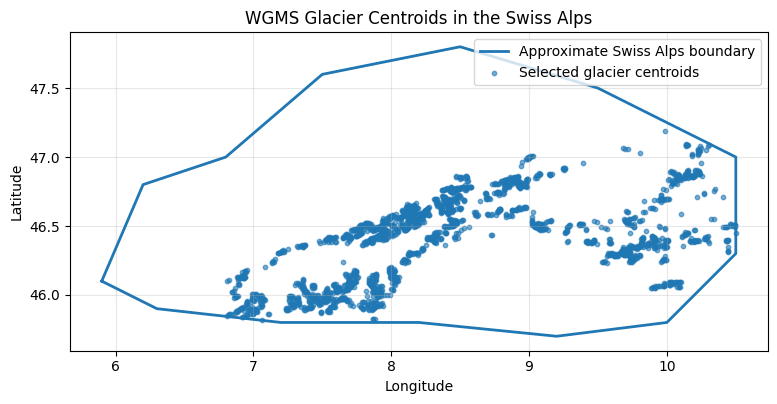

,area_weighted_mwe,mean_mwe,glaciers_with_data,area_with_data
year,,,,
1915,0.833693,1.004664,2076,1279.631
1916,0.982452,1.153583,2076,1279.631
1917,-0.115754,0.055376,2076,1279.631
1918,0.625993,0.797280,2076,1279.631
1919,0.365445,0.523442,2076,1279.631
...,...,...,...,...
2021,-0.520860,-0.317153,2076,1279.631
2022,-3.213263,-3.060091,2076,1279.631
2023,-2.180007,-2.029042,2076,1279.631


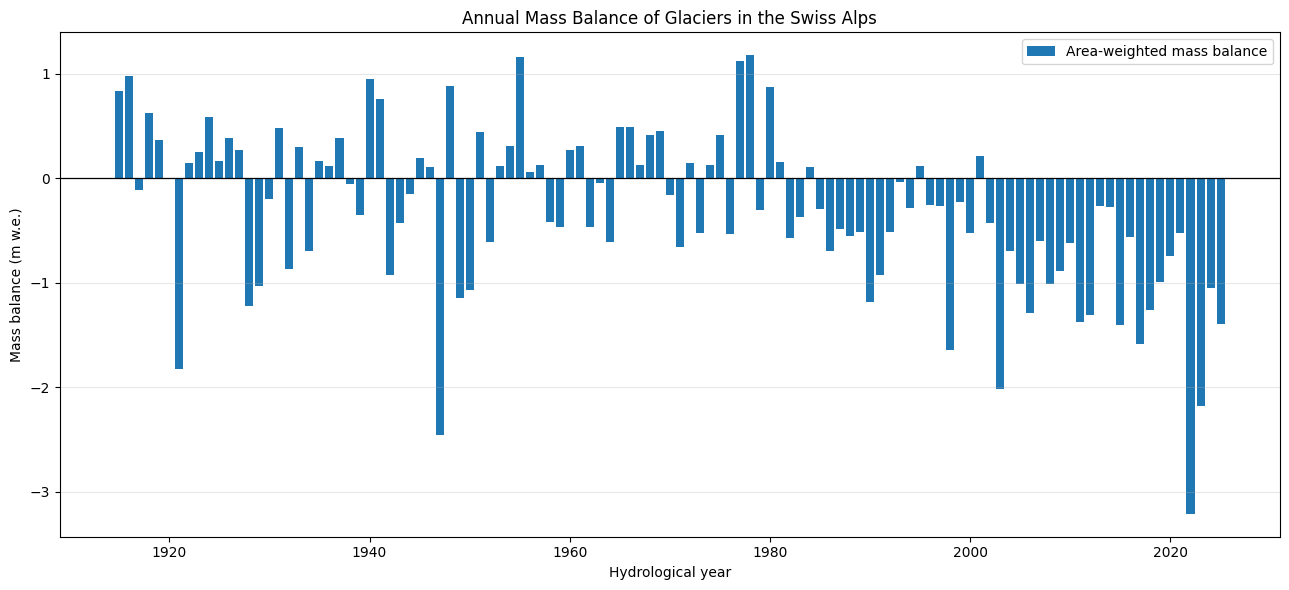

In [2]:

folder = Path("wgms-amce-2026-02-10/glacier")

# 1. Rough Swiss Alps boundary (longitude, latitude)
swiss_alps_coords = [
    (5.9, 46.1),
    (6.2, 46.8),
    (6.8, 47.0),
    (7.5, 47.6),
    (8.5, 47.8),
    (9.5, 47.5),
    (10.5, 47.0),
    (10.5, 46.3),
    (10.0, 45.8),
    (9.2, 45.7),
    (8.2, 45.8),
    (7.2, 45.8),
    (6.3, 45.9),
    (5.9, 46.1)
]

swiss_alps = Polygon(swiss_alps_coords)

# 2. Read all regional glacier metadata
metadata_parts = []

for file in folder.glob("*_metadata.csv"):
    region = file.stem.replace("_metadata", "")
    df = pd.read_csv(file)

    required = {"outline_id", "latitude", "longitude", "area_km2"}
    if not required.issubset(df.columns):
        continue

    for col in ["latitude", "longitude", "area_km2"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["region"] = region
    metadata_parts.append(df)

metadata = pd.concat(metadata_parts, ignore_index=True)
metadata = metadata.dropna(
    subset=["latitude", "longitude", "area_km2"]
)

# 3. Select glaciers inside polygon
inside = metadata.apply(
    lambda r: swiss_alps.covers(
        Point(r["longitude"], r["latitude"])
    ),
    axis=1
)

glaciers = metadata.loc[inside].copy()
glaciers = glaciers.drop_duplicates(
    subset=["region", "outline_id"]
)

print("Glaciers inside Swiss Alps:", len(glaciers))
print("Total inventory glacier area (km²):",
      round(glaciers["area_km2"].sum(), 2))

display(
    glaciers.sort_values("area_km2", ascending=False)[
        ["region", "outline_id", "latitude",
         "longitude", "area_km2"]
    ]
)

# 4. Plot boundary and selected glaciers
fig, ax = plt.subplots(figsize=(9, 8))

x, y = swiss_alps.exterior.xy
ax.plot(x, y, linewidth=2, label="Approximate Swiss Alps boundary")

ax.scatter(
    glaciers["longitude"], glaciers["latitude"],
    s=10, alpha=0.6, label="Selected glacier centroids"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("WGMS Glacier Centroids in the Swiss Alps")
ax.legend()
ax.grid(alpha=0.3)
ax.set_aspect("equal")
plt.show()

# 5. Load annual mass-change data
mass_parts = []

for region, group in glaciers.groupby("region"):
    mass_file = folder / f"{region}_mwe.csv"

    if not mass_file.exists():
        print(f"Missing mass file: {mass_file.name}")
        continue

    mass = pd.read_csv(mass_file)
    year_cols = [c for c in mass.columns if str(c).isdigit()]

    if not year_cols:
        continue

    selected = group[["outline_id", "area_km2"]].merge(
        mass[["outline_id"] + year_cols],
        on="outline_id",
        how="inner"
    )

    if selected.empty:
        continue

    long = selected.melt(
        id_vars=["outline_id", "area_km2"],
        value_vars=year_cols,
        var_name="year",
        value_name="mass_change_mwe"
    )

    long["year"] = pd.to_numeric(long["year"])
    long["mass_change_mwe"] = pd.to_numeric(
        long["mass_change_mwe"], errors="coerce"
    )

    mass_parts.append(long)

if not mass_parts:
    raise ValueError("No matching annual mass-change records found.")

data = pd.concat(mass_parts, ignore_index=True)
data = data.dropna(subset=["mass_change_mwe", "area_km2"])
data = data[data["area_km2"] > 0]

# 6. Calculate area-weighted annual mass balance
data["weighted_change"] = (
    data["mass_change_mwe"] * data["area_km2"]
)

annual = data.groupby("year").agg(
    weighted_sum=("weighted_change", "sum"),
    area_with_data=("area_km2", "sum"),
    glaciers_with_data=("outline_id", "nunique"),
    mean_mwe=("mass_change_mwe", "mean")
)

annual["area_weighted_mwe"] = (
    annual["weighted_sum"] / annual["area_with_data"]
)

annual.index = annual.index.astype(int)
annual.index.name = "year"

display(annual[[
    "area_weighted_mwe",
    "mean_mwe",
    "glaciers_with_data",
    "area_with_data"
]])

# 7. Plot annual regional mass balance
fig, ax = plt.subplots(figsize=(13, 6))

ax.bar(
    annual.index,
    annual["area_weighted_mwe"],
    label="Area-weighted mass balance"
)

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlabel("Hydrological year")
ax.set_ylabel("Mass balance (m w.e.)")
ax.set_title("Annual Mass Balance of Glaciers in the Swiss Alps")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

swiss_alps_annual = annual.copy()

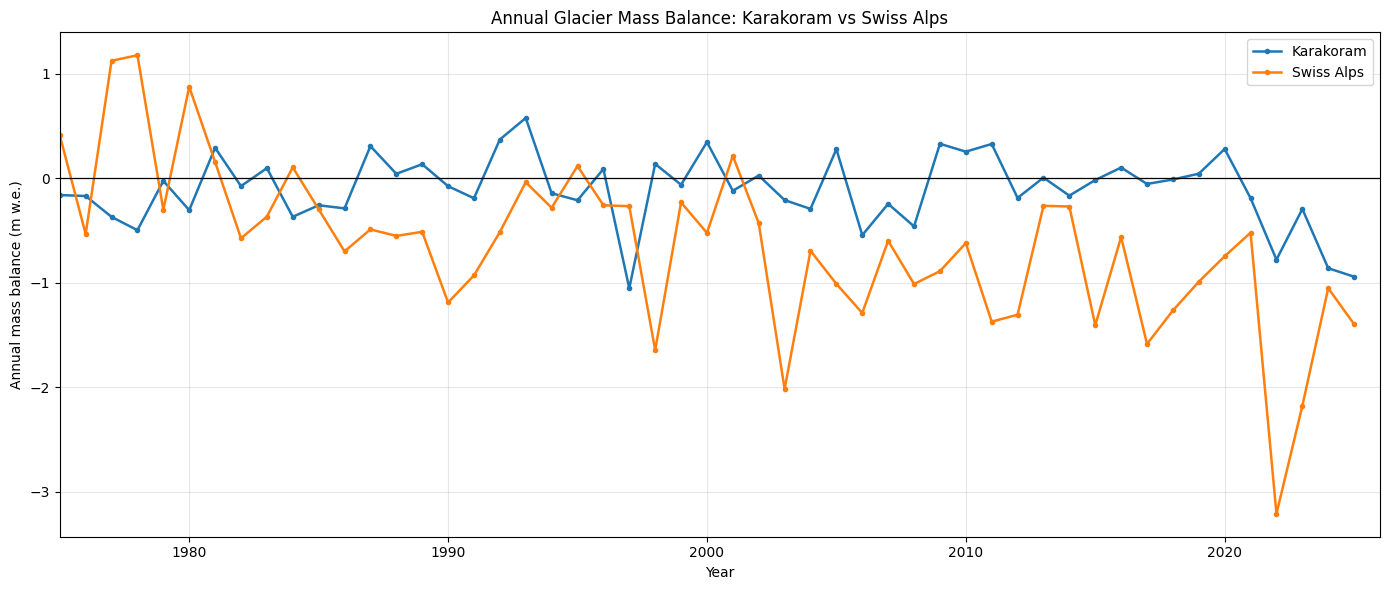

In [3]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    karakoram_annual.index,
    karakoram_annual["area_weighted_mwe"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Karakoram"
)

ax.plot(
    swiss_alps_annual.index,
    swiss_alps_annual["area_weighted_mwe"],
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Swiss Alps"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xlim(1975, 2026)
ax.set_xlabel("Year")
ax.set_ylabel("Annual mass balance (m w.e.)")
ax.set_title("Annual Glacier Mass Balance: Karakoram vs Swiss Alps")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### this is not as useful because we can't see the cumulative effect, lets try doing that

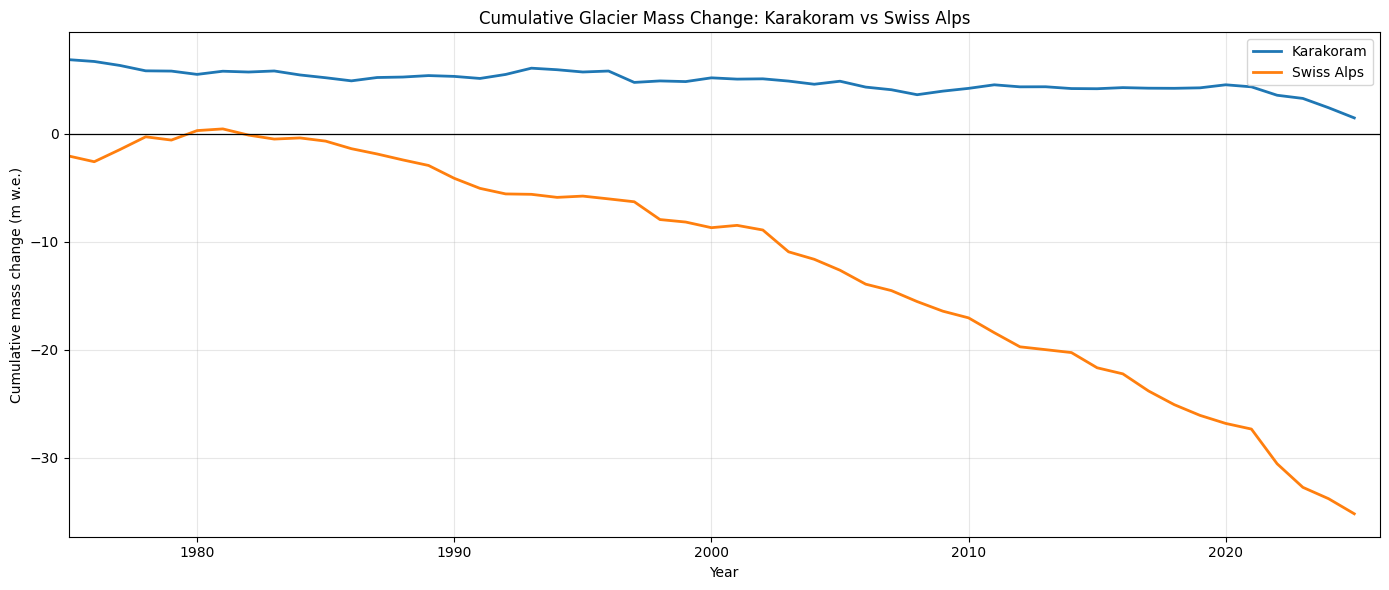

In [4]:
karakoram_cumulative = karakoram_annual["area_weighted_mwe"].cumsum()
swiss_alps_cumulative = swiss_alps_annual["area_weighted_mwe"].cumsum()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    karakoram_cumulative.index,
    karakoram_cumulative.values,
    linewidth=2,
    label="Karakoram"
)

ax.plot(
    swiss_alps_cumulative.index,
    swiss_alps_cumulative.values,
    linewidth=2,
    label="Swiss Alps"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xlim(1975, 2026)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title("Cumulative Glacier Mass Change: Karakoram vs Swiss Alps")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### We can clearly see that the data is showing a trend but we need to just adjust the data so they start at the same starting point

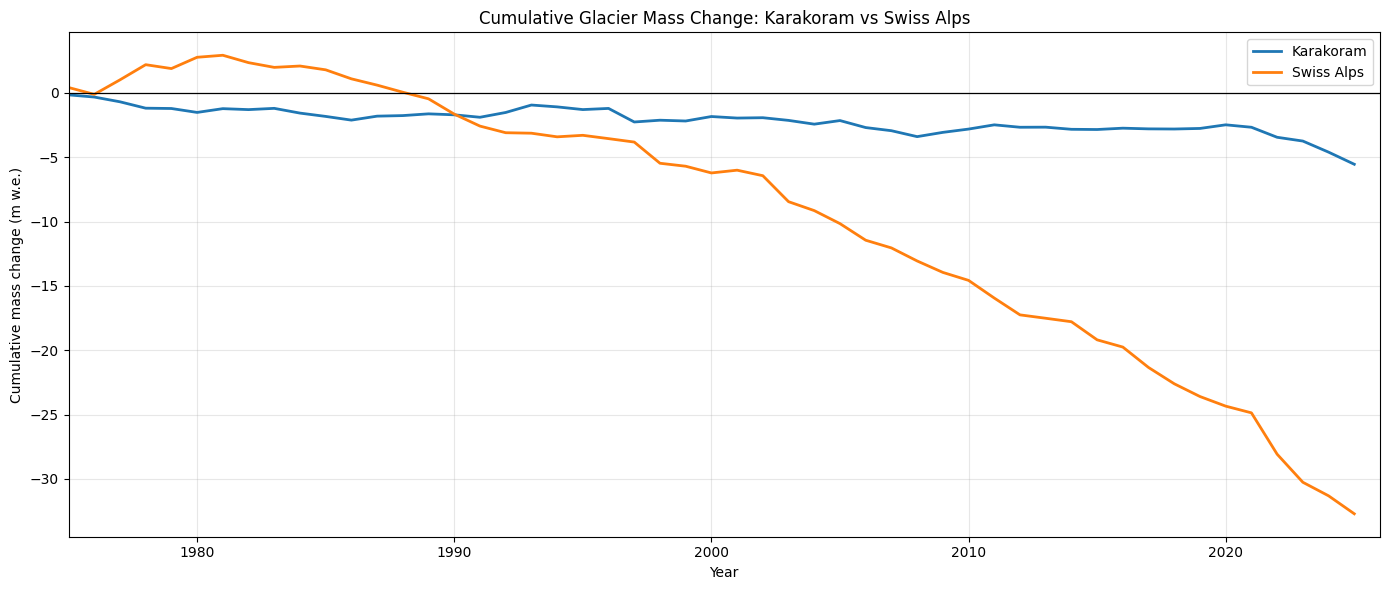

In [5]:
start = 1975

k = karakoram_annual.loc[start:, "area_weighted_mwe"]
s = swiss_alps_annual.loc[start:, "area_weighted_mwe"]

karakoram_cumulative = k.cumsum()
swiss_alps_cumulative = s.cumsum()

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    karakoram_cumulative.index,
    karakoram_cumulative.values,
    linewidth=2,
    label="Karakoram"
)

ax.plot(
    swiss_alps_cumulative.index,
    swiss_alps_cumulative.values,
    linewidth=2,
    label="Swiss Alps"
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xlim(1975, 2026)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title("Cumulative Glacier Mass Change: Karakoram vs Swiss Alps")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Even though these are absolute values these work because: It’s mass per unit area, so a small glacier and a large one can be compared directly. A 1 km² glacier at −1 m w.e. lost 1 million m³ of water equivalent (1 million tonnes). A 100 km² glacier at −1 m w.e. lost 100 million tonnes.

---

### I created a function to calculate the regional mass balance for any given polygon coordinates. This function takes a list of (longitude, latitude) tuples defining the polygon and a name for the region. It returns the selected glaciers and their annual mass balance data.

Glaciers inside Andes boundary: 5823
Total inventory glacier area (km²): 3892.69


,region,outline_id,latitude,longitude,area_km2
67627,SA2,RGI60-17.01218,-34.60720,-70.3361,110.978
71795,SA2,RGI60-17.13796,-33.49150,-69.7567,69.313
71798,SA2,RGI60-17.13799,-33.38160,-69.7313,29.768
72017,SA2,RGI60-17.14015,-33.09350,-70.1163,24.719
71703,SA2,RGI60-17.13704,-33.71190,-69.9002,23.266
...,...,...,...,...,...
145180,TRP,RGI60-16.02113,-13.04810,-75.0568,0.010
145181,TRP,RGI60-16.02114,-9.52674,-77.3811,0.010
70712,SA2,RGI60-17.12716,-38.69680,-71.7858,0.010
70589,SA2,RGI60-17.12593,-38.98120,-71.5519,0.010


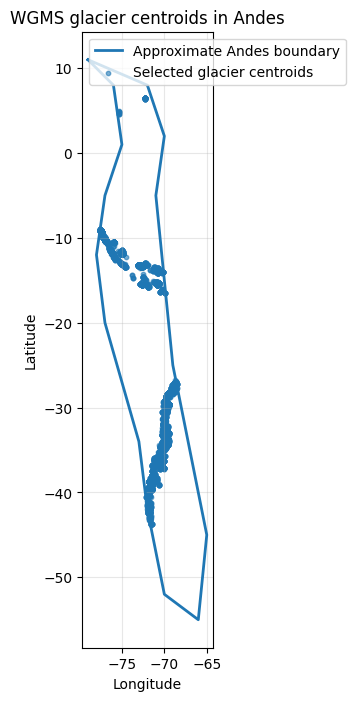

,area_weighted_mwe,mean_mwe,glaciers_with_data,area_with_data
year,,,,
1976,-0.485554,-0.385778,5823,4003.885
1977,-0.650884,-0.550772,5823,4003.885
1978,-0.006428,0.092224,5823,4003.885
1979,0.207099,0.305211,5823,4003.885
1980,0.046111,0.144568,5823,4003.885
1981,0.072379,0.170740,5823,4003.885
1982,-1.137934,-1.036936,5823,4003.885
1983,1.526816,1.621890,5823,4003.885
1984,-0.623784,-0.523995,5823,4003.885


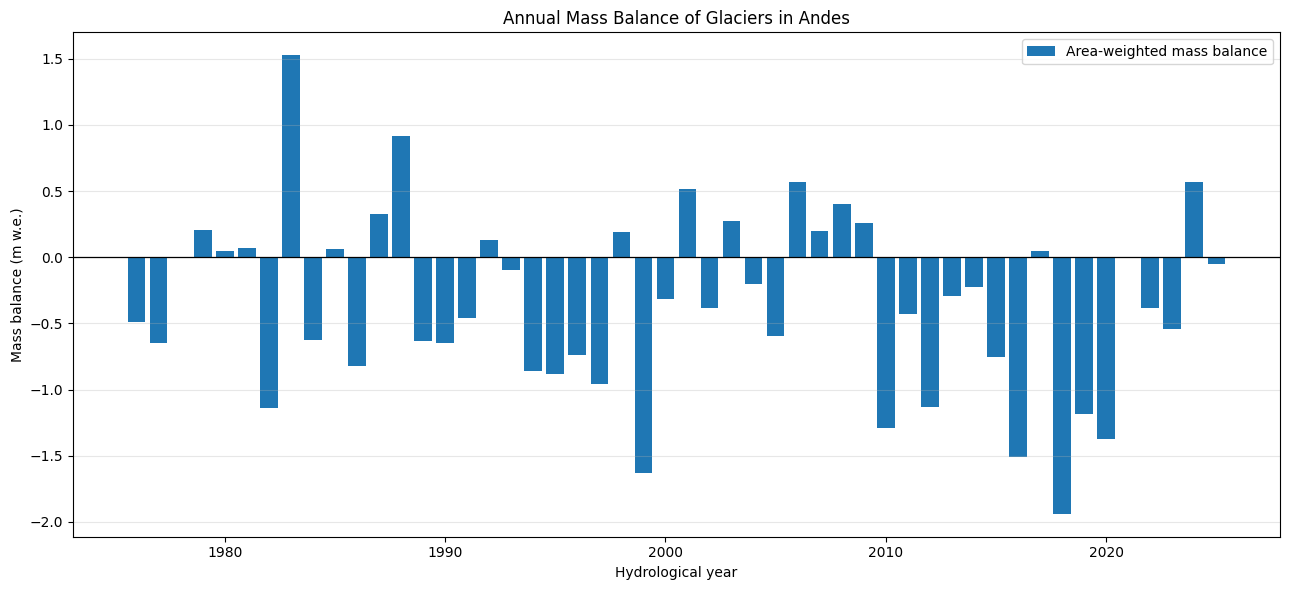

In [6]:
from wgms_exploration import regional_mass_balance

andes_coords = [
    (-79.0, 11.0),
    (-76.0, 8.0),
    (-75.0, 1.0),
    (-77.0, -5.0),
    (-78.0, -12.0),
    (-77.0, -20.0),
    (-75.0, -27.0),
    (-73.0, -34.0),
    (-72.0, -42.0),
    (-70.0, -52.0),
    (-66.0, -55.0),
    (-65.0, -45.0),
    (-67.0, -35.0),
    (-69.0, -25.0),
    (-70.0, -15.0),
    (-71.0, -5.0),
    (-70.0, 2.0),
    (-72.0, 8.0),
    (-79.0, 11.0)
]

glaciers_p, andes_annual = regional_mass_balance(andes_coords, "Andes")




In [7]:
kunlun_coords = [
    (77.0, 36.0),
    (78.0, 36.8),
    (80.0, 37.5),
    (82.0, 37.8),
    (84.0, 37.5),
    (86.0, 37.0),
    (88.0, 36.5),
    (90.0, 36.0),
    (92.0, 35.5),
    (94.0, 35.0),
    (96.0, 34.5),
    (98.0, 34.0),
    (99.0, 33.0),
    (97.0, 32.5),
    (94.0, 33.0),
    (91.0, 33.5),
    (88.0, 34.0),
    (85.0, 34.5),
    (82.0, 35.0),
    (79.0, 35.5),
    (77.0, 36.0)
]

kunlun_glaciers, kunlun_annual = regional_mass_balance(kunlun_coords, "Kunlun",verbose=False,plot=False)

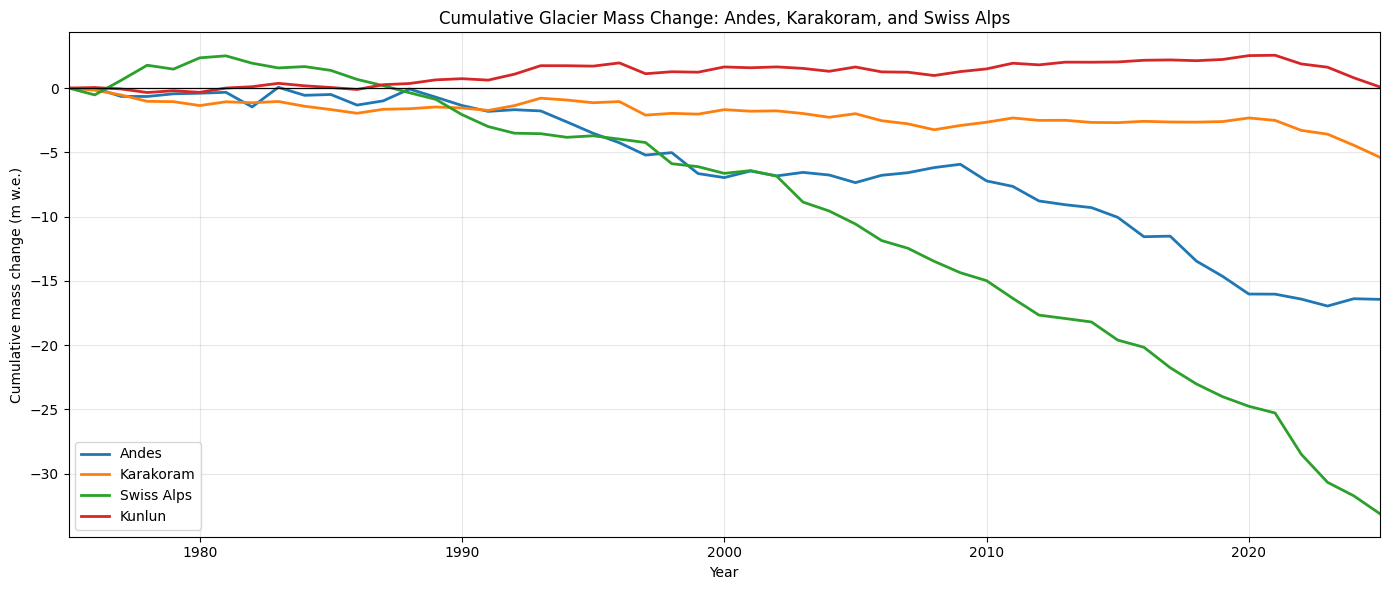

In [8]:
start = 1975

regional_annual = {
    "Andes": andes_annual,
    "Karakoram": karakoram_annual,
    "Swiss Alps": swiss_alps_annual,
    "Kunlun": kunlun_annual
}

fig, ax = plt.subplots(figsize=(14, 6))

for name, annual_data in regional_annual.items():
    series = annual_data.loc[
        start:, "area_weighted_mwe"
    ].dropna()

    cumulative = series.cumsum()
    cumulative = cumulative - cumulative.iloc[0]

    ax.plot(
        cumulative.index,
        cumulative.values,
        linewidth=2,
        label=name
    )

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlim(start, 2025)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title(
    "Cumulative Glacier Mass Change: Andes, Karakoram, and Swiss Alps"
)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
from wgms_exploration import load_wgms_metadata, regional_mass_balance

In [12]:
REGIONS = {
    # Near the Karakoram (the anomaly question)
    "Pamir":             [(70.5, 36.5),(72.0, 36.0),(73.5, 36.5),(75.5, 37.0),(76.5, 38.0),(75.5, 39.5),(73.5, 40.0),(71.5, 39.5),(70.5, 38.5),(70.5, 36.5)],
    "Hindu Kush":       [(69, 34.5), (73, 34.5), (73, 37), (69, 37)],
    "Tien Shan":        [(69, 40), (82, 40), (82, 44), (69, 44)],
    "Central Himalaya": [(80, 27), (89, 27), (89, 30), (80, 30)],
    "Eastern Himalaya": [(89, 27), (97, 27), (97, 30), (89, 30)],

    # Global comparison regions
    "Scandinavia":      [(5, 59.5), (9, 59.5), (9, 70), (5, 70)],
    "Svalbard":         [(10, 76.5), (35, 76.5), (35, 80.5), (10, 80.5)],
    "Caucasus":         [(37, 41), (49, 41), (49, 44), (37, 44)],
    "Alaska":           [(-153, 58), (-130, 58), (-130, 64), (-153, 64)],
    "Patagonia":        [(-75, -52), (-72, -52), (-72, -46), (-75, -46)],
    "New Zealand":      [(167, -46), (172, -46), (172, -43), (167, -43)],
}


meta = load_wgms_metadata()
results = {}
for name, coords in REGIONS.items():
    try:
        g, a = regional_mass_balance(coords, name, metadata=meta,
                                     plot=False, verbose=False)
        results[name] = a
        print(f"{name}: {len(g)} glaciers, {a.index.min()}-{a.index.max()}")
    except ValueError:
        print(f"{name}: no data")

Pamir: 14149 glaciers, 1957-2025
Hindu Kush: 4449 glaciers, 1957-2025
Tien Shan: 8862 glaciers, 1957-2025
Central Himalaya: 6291 glaciers, 1957-2025
Eastern Himalaya: 4966 glaciers, 1957-2025
Scandinavia: 1536 glaciers, 1946-2025
Svalbard: 1567 glaciers, 1946-2025
Caucasus: 2016 glaciers, 1953-2025
Alaska: 18036 glaciers, 1946-2025
Patagonia: 5821 glaciers, 1976-2025
New Zealand: 3403 glaciers, 1976-2025


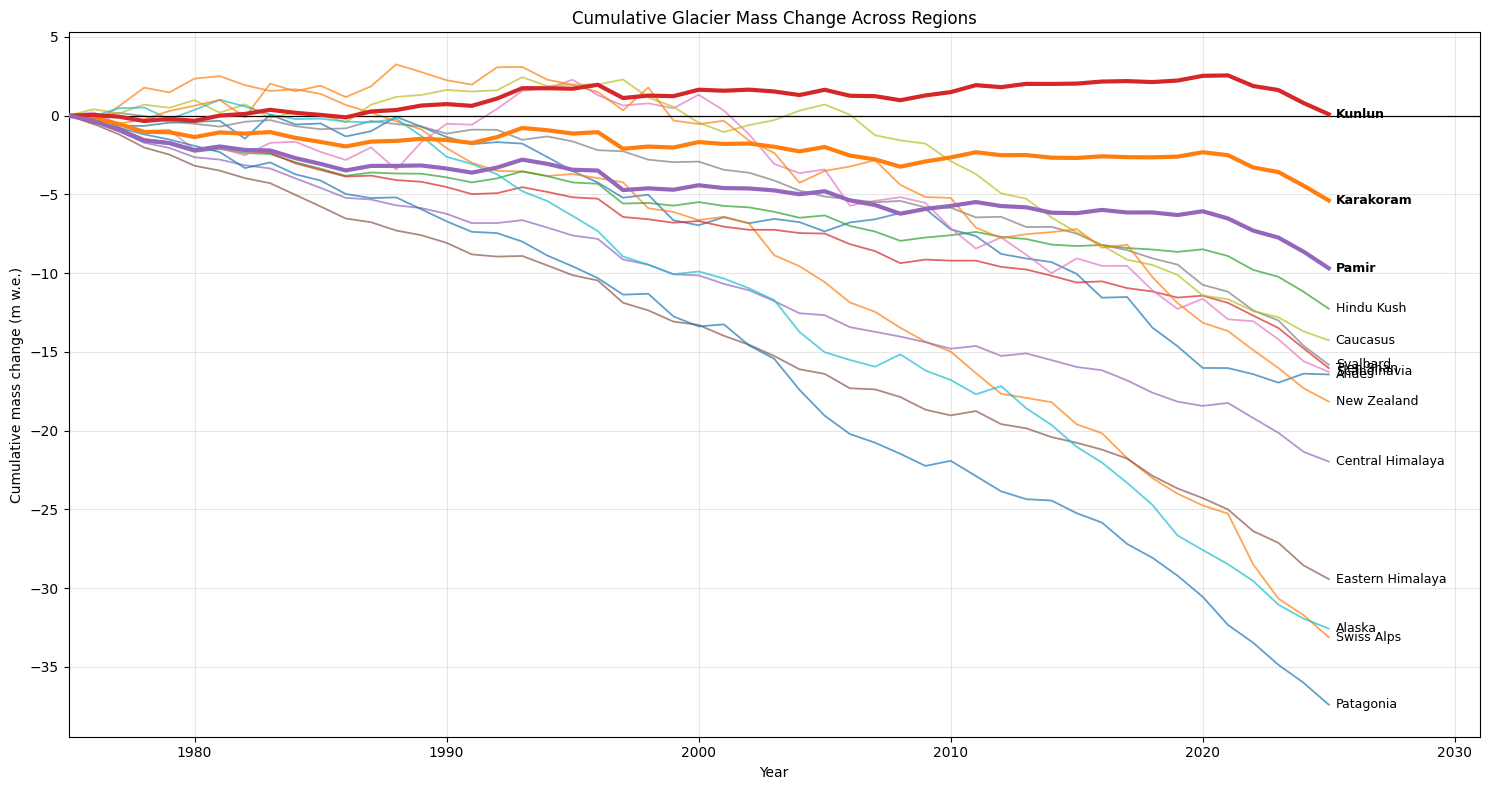

In [13]:
import matplotlib.pyplot as plt

all_regions = {
    "Andes": andes_annual,
    "Karakoram": karakoram_annual,
    "Kunlun": kunlun_annual,
    "Swiss Alps": swiss_alps_annual,
    **results,   # Pamir, Hindu Kush, Tien Shan, etc. from the REGIONS loop
}

start, end = 1975, 2025
highlight = {"Karakoram": "tab:orange", "Kunlun": "tab:red", "Pamir": "tab:purple"}
min_years = 10 

fig, ax = plt.subplots(figsize=(15, 8))

for name, annual in all_regions.items():
    series = annual.loc[start:end, "area_weighted_mwe"].dropna()
    if len(series) < min_years:
        print(f"Skipping {name}: only {len(series)} years of data")
        continue

    cum = series.cumsum()
    cum = cum - cum.iloc[0]          # every line starts at 0

    if name in highlight:
        ax.plot(cum.index, cum.values, linewidth=3, color=highlight[name], zorder=3)
    else:
        ax.plot(cum.index, cum.values, linewidth=1.3, alpha=0.7)

    ax.annotate(name, (cum.index[-1], cum.values[-1]),
                xytext=(5, 0), textcoords="offset points",
                fontsize=9, va="center",
                fontweight="bold" if name in highlight else "normal")

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlim(start, end + 6)          # extra room for the labels
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title("Cumulative Glacier Mass Change Across Regions")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:

from scipy import stats

def stability_summary(annual, start=2000, end=2025, tol=0.15):
    s = annual.loc[start:end, "area_weighted_mwe"].dropna()
    n = len(s)
    mean = s.mean()
    sem = s.std(ddof=1) / np.sqrt(n)
    lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
    t, p = stats.ttest_1samp(s, 0)
    slope = stats.linregress(s.index, s.values).slope
    return {
        "years": n,
        "mean_mwe_per_yr": round(mean, 3),
        "95%_CI": (round(lo, 3), round(hi, 3)),
        "p_vs_zero": round(p, 3),
        "within_tol": abs(mean) <= tol,
        "ci_includes_zero": lo <= 0 <= hi,
        "trend_per_yr": round(slope, 4),
    }

summary = pd.DataFrame({name: stability_summary(a) for name, a in all_regions.items()}).T
summary

,years,mean_mwe_per_yr,95%_CI,p_vs_zero,within_tol,ci_includes_zero,trend_per_yr
Andes,26,-0.376,"(-0.641, -0.112)",0.01,False,False,-0.0254
Karakoram,26,-0.129,"(-0.268, 0.01)",0.08,True,True,-0.019
Kunlun,26,-0.044,"(-0.171, 0.083)",0.501,True,True,-0.0185
Swiss Alps,26,-1.039,"(-1.309, -0.768)",0.0,False,False,-0.0374
Pamir,26,-0.192,"(-0.334, -0.049)",0.014,False,False,-0.0222
Hindu Kush,26,-0.252,"(-0.392, -0.112)",0.002,False,False,-0.0201
Tien Shan,26,-0.355,"(-0.507, -0.204)",0.0,False,False,-0.0273
Central Himalaya,26,-0.457,"(-0.593, -0.322)",0.0,False,False,-0.0128
Eastern Himalaya,26,-0.629,"(-0.773, -0.485)",0.0,False,False,-0.0213
Scandinavia,26,-0.644,"(-0.995, -0.292)",0.001,False,False,-0.0034


![Map](maps/map.png)

      Actual  Predicted
2016   0.103     -0.019
2017  -0.054     -0.131
2018  -0.011     -0.065
2019   0.044      0.004
2020   0.281     -0.168
2021  -0.189     -0.069
2022  -0.779     -0.030
2023  -0.293     -0.140
2024  -0.861     -0.093
2025  -0.942      0.005

MAE: 0.348
RMSE: 0.481
R²: -0.343


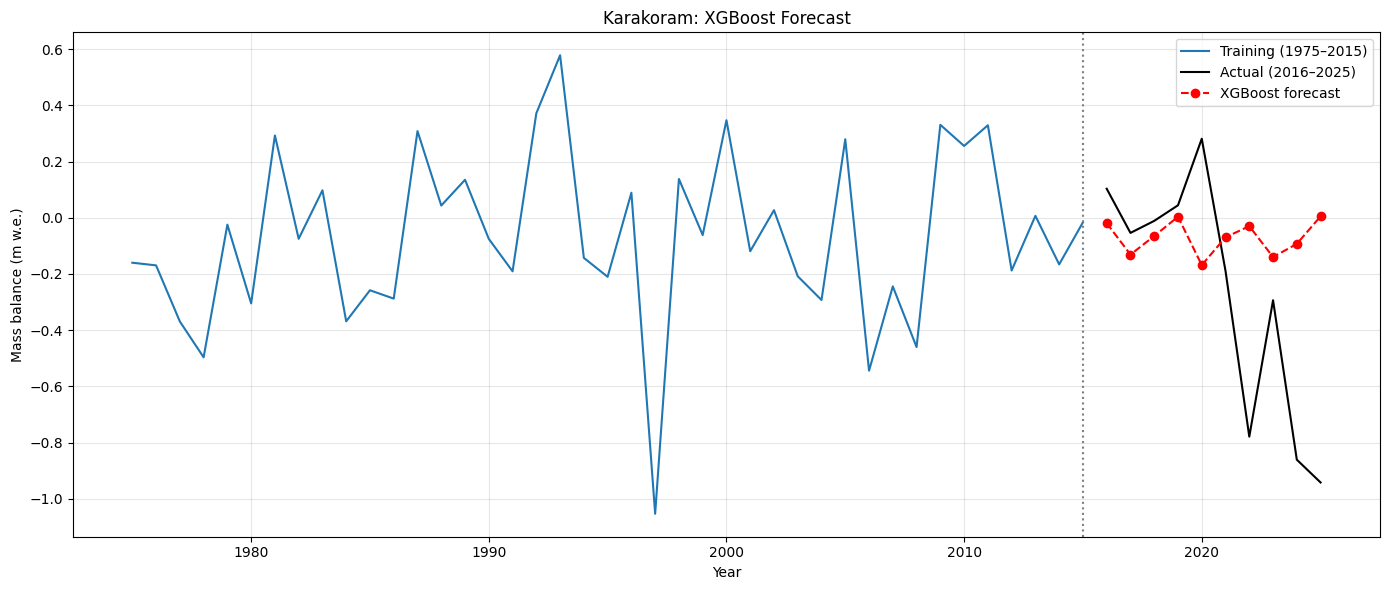

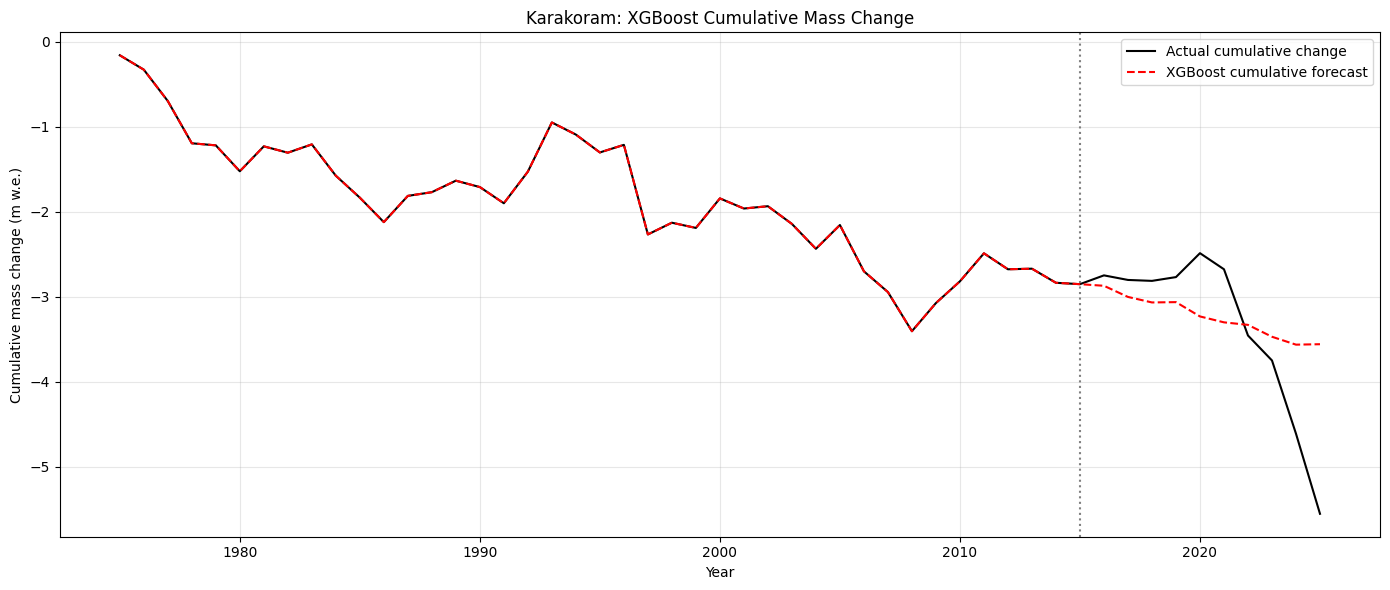

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare data
series = karakoram_annual["area_weighted_mwe"].copy()
series.index = pd.to_numeric(series.index)
series = pd.to_numeric(series).sort_index().loc[1975:2025]

# Create lag features
data = pd.DataFrame({"mwe": series})

for lag in range(1, 6):
    data[f"lag_{lag}"] = data["mwe"].shift(lag)

data["year"] = data.index
data = data.dropna()

features = ["year"] + [f"lag_{i}" for i in range(1, 6)]

train = data.loc[1975:2015]

X_train = train[features]
y_train = train["mwe"]

# Fit XGBoost
model = XGBRegressor(
    n_estimators=200,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

# Recursive forecast 2016–2025
history = series.loc[1975:2015].tolist()
predictions = {}

for year in range(2016, 2026):

    row = {
        "year": year,
        **{f"lag_{i}": history[-i] for i in range(1, 6)}
    }

    prediction = model.predict(pd.DataFrame([row])[features])[0]

    predictions[year] = prediction
    history.append(prediction)

predicted = pd.Series(predictions)
actual = series.loc[2016:2025]

# Evaluation
comparison = pd.DataFrame({
    "Actual": actual,
    "Predicted": predicted
}).dropna()

print(comparison.round(3))
print("\nMAE:", round(mean_absolute_error(comparison.Actual, comparison.Predicted), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(comparison.Actual, comparison.Predicted)), 3))
print("R²:", round(r2_score(comparison.Actual, comparison.Predicted), 3))

# Plot annual mass balance
plt.figure(figsize=(14, 6))
plt.plot(series.loc[1975:2015].index, series.loc[1975:2015], label="Training (1975–2015)")
plt.plot(actual.index, actual, color="black", label="Actual (2016–2025)")
plt.plot(predicted.index, predicted, "r--o", label="XGBoost forecast")
plt.axvline(2015, color="gray", linestyle=":")
plt.xlabel("Year")
plt.ylabel("Mass balance (m w.e.)")
plt.title("Karakoram: XGBoost Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot cumulative mass change
actual_cum = series.loc[1975:2025].cumsum()
predicted_cum = pd.concat([
    series.loc[1975:2015],
    predicted
]).cumsum()

plt.figure(figsize=(14, 6))
plt.plot(actual_cum.index, actual_cum, color="black", label="Actual cumulative change")
plt.plot(predicted_cum.index, predicted_cum, "r--", label="XGBoost cumulative forecast")
plt.axvline(2015, color="gray", linestyle=":")
plt.xlabel("Year")
plt.ylabel("Cumulative mass change (m w.e.)")
plt.title("Karakoram: XGBoost Cumulative Mass Change")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### This is actually a very poor model as we have very few points and data sources to predict the upcoming years, in my upcoming approach I will try adding more data sources such as weather (precipitation + other atmosphere sources) and for that I will need to use smaller boxes instead of ranges such as Karakoram or Kunlun, so I will draw boxes of e.g 25x25 km and treat them as isolate boxes so that I have more points to learn from!

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from wgms_exploration import load_wgms_metadata, regional_mass_balance

# --- settings ---
BOX_KM = 25
LON_MIN, LON_MAX = 72.5, 79.0
LAT_MIN, LAT_MAX = 34.2, 38.0
MIN_YEARS = 10        # skip boxes with too little data
MIN_GLACIERS = 1      # raise this to require more glaciers per box


def make_grid(lon_min, lon_max, lat_min, lat_max, box_km=25):
    """Return {box_id: [(lon, lat), ...]} covering the rectangle, numbered row by row."""
    dlat = box_km / 111.0
    dlon = box_km / (111.0 * np.cos(np.radians((lat_min + lat_max) / 2)))
    boxes, i = {}, 1
    for lat0 in np.arange(lat_min, lat_max, dlat):
        for lon0 in np.arange(lon_min, lon_max, dlon):
            boxes[i] = [(lon0, lat0), (lon0 + dlon, lat0),
                        (lon0 + dlon, lat0 + dlat), (lon0, lat0 + dlat),
                        (lon0, lat0)]
            i += 1
    return boxes


boxes = make_grid(LON_MIN, LON_MAX, LAT_MIN, LAT_MAX, BOX_KM)
print(f"{len(boxes)} boxes of ~{BOX_KM} km")

# Load once, then keep only glaciers inside the overall rectangle (much faster per box)
meta = load_wgms_metadata()
meta_k = meta[meta["longitude"].between(LON_MIN, LON_MAX)
              & meta["latitude"].between(LAT_MIN, LAT_MAX)]

box_annual, box_info = {}, []
for bid, coords in boxes.items():
    try:
        g, a = regional_mass_balance(coords, f"Box {bid}", metadata=meta_k,
                                     plot=False, verbose=False)
    except ValueError:
        continue   # no glaciers or no mass data in this box

    n_years = a["area_weighted_mwe"].dropna().shape[0]
    n_glac = a["glaciers_with_data"].max()
    if n_years < MIN_YEARS or n_glac < MIN_GLACIERS:
        continue

    box_annual[bid] = a
    box_info.append({"box": bid, "glaciers": n_glac, "years": n_years,
                     "first_year": a.index.min(), "last_year": a.index.max()})

import pandas as pd
box_info = pd.DataFrame(box_info).set_index("box")
print(f"{len(box_annual)} boxes have usable data")
box_info

408 boxes of ~25 km
310 boxes have usable data


,glaciers,years,first_year,last_year
box,,,,
6,1,69,1957,2025
9,10,69,1957,2025
10,27,69,1957,2025
11,111,69,1957,2025
12,88,69,1957,2025
...,...,...,...,...
389,17,69,1957,2025
393,19,69,1957,2025
394,4,69,1957,2025


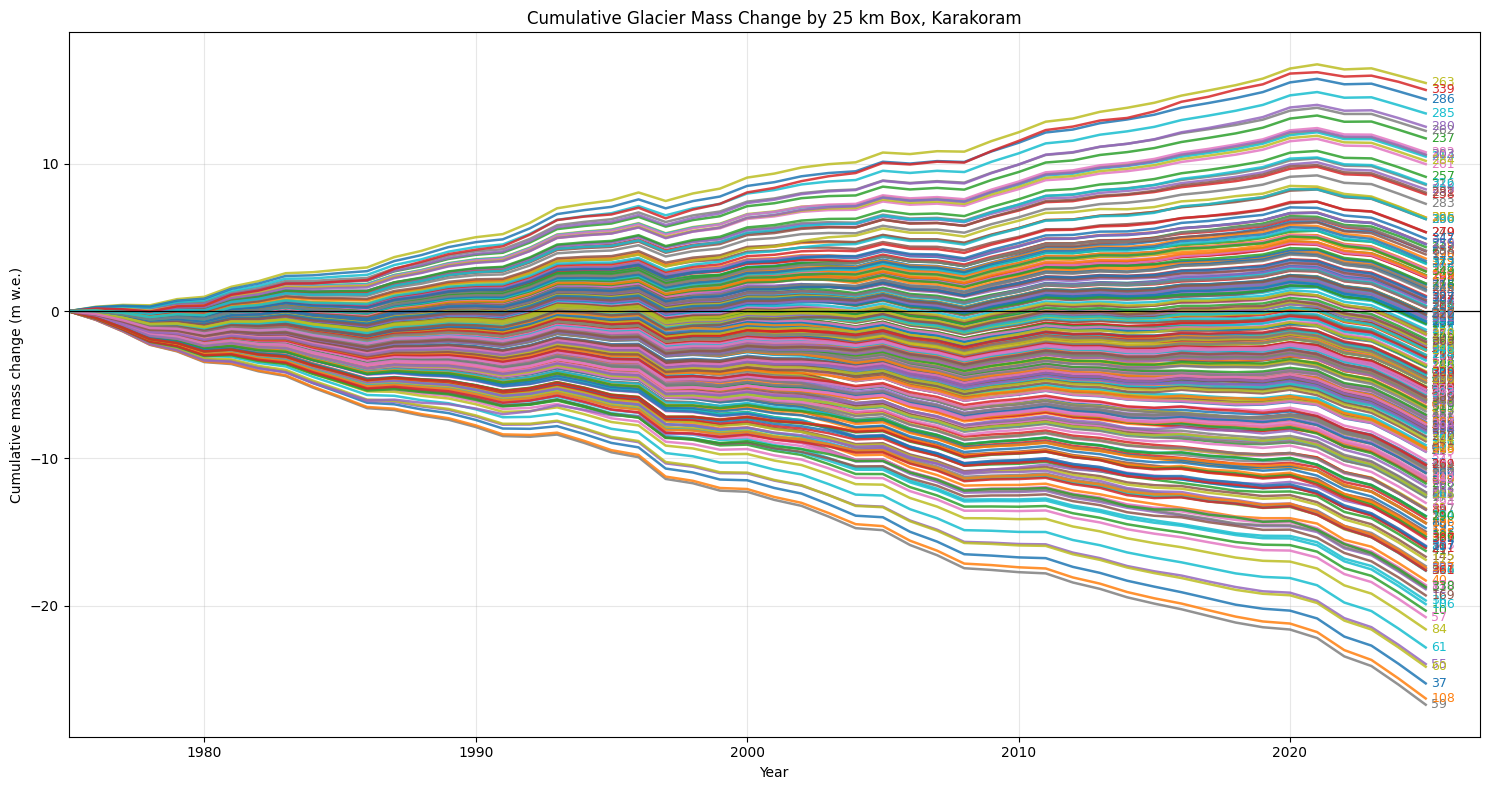

In [17]:
start, end = 1975, 2025

fig, ax = plt.subplots(figsize=(15, 8))

for bid, annual in box_annual.items():
    s = annual.loc[start:end, "area_weighted_mwe"].dropna()
    if s.empty:
        continue
    cum = s.cumsum()
    cum = cum - cum.iloc[0]          # each line starts at 0

    line, = ax.plot(cum.index, cum.values, linewidth=1.8, alpha=0.85)
    ax.annotate(str(bid), (cum.index[-1], cum.values[-1]),
                xytext=(4, 0), textcoords="offset points",
                fontsize=9, color=line.get_color(), va="center")

ax.axhline(0, color="black", linewidth=0.9)
ax.set_xlim(start, end + 2)
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative mass change (m w.e.)")
ax.set_title(f"Cumulative Glacier Mass Change by {BOX_KM} km Box, Karakoram")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### this clearly shows that the glaciers in the karakoram are not all behaving similarly! Also it's not exact coordinates of karakoram a rough drawing, and the term matters less then a boundary that is between where glaciers are growing and receding because that could be in the middle of a range

In [18]:
import folium
import pandas as pd
from pathlib import Path
from matplotlib import colormaps, colors
from branca.colormap import LinearColormap

# --- settings ---
START, END = 2000, 2025      # period to accumulate over (the anomaly is usually described post-2000)
STABLE_TOL = 0.15            # m w.e./yr: boxes with |mean annual balance| below this are drawn white

# 1. Cumulative mass change per box over the chosen period
rows = []
for bid, a in box_annual.items():
    s = a.loc[START:END, "area_weighted_mwe"].dropna()
    if len(s) < MIN_YEARS:
        continue
    rows.append({
        "box": bid,
        "cumulative_mwe": s.sum(),
        "mean_mwe_yr": s.mean(),
        "years": len(s),
        "glaciers": int(a.loc[START:END, "glaciers_with_data"].max()),
    })
box_stats = pd.DataFrame(rows).set_index("box")

# 2. Colour scale: red = losing, white = 0, blue = gaining (symmetric around zero)
vmax = box_stats["cumulative_mwe"].abs().max()
norm = colors.TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
cmap = colormaps["RdBu"]          # low = red, middle = white, high = blue

def box_color(row):
    if abs(row["mean_mwe_yr"]) <= STABLE_TOL:
        return "#ffffff"          # stable
    return colors.to_hex(cmap(norm(row["cumulative_mwe"])))

# 3. Build the interactive map
lat_c = (LAT_MIN + LAT_MAX) / 2
lon_c = (LON_MIN + LON_MAX) / 2
m = folium.Map(location=[lat_c, lon_c], zoom_start=7, tiles="CartoDB positron")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri World Imagery", name="Satellite",
).add_to(m)

# boxes with no usable data: thin grey outline only
for bid, coords in boxes.items():
    if bid in box_stats.index:
        continue
    folium.Polygon(
        locations=[(lat, lon) for lon, lat in coords],     # folium wants (lat, lon)
        color="grey", weight=0.5, fill=False,
    ).add_to(m)

# boxes with data: coloured, numbered, with a tooltip
for bid, row in box_stats.iterrows():
    coords = boxes[bid]
    locs = [(lat, lon) for lon, lat in coords]
    tip = (f"<b>Box {bid}</b><br>"
           f"Cumulative {START}-{END}: {row['cumulative_mwe']:.2f} m w.e.<br>"
           f"Mean: {row['mean_mwe_yr']:.3f} m w.e./yr<br>"
           f"Years with data: {row['years']}<br>"
           f"Glaciers: {row['glaciers']}")
    folium.Polygon(
        locations=locs, color="black", weight=1,
        fill=True, fill_color=box_color(row), fill_opacity=0.75,
        tooltip=tip,
    ).add_to(m)

    lons, lats = zip(*coords[:-1])
    folium.Marker(
        location=[sum(lats) / len(lats), sum(lons) / len(lons)],
        icon=folium.DivIcon(
            icon_size=(30, 30), icon_anchor=(15, 15),
            html=f'<div style="font-size:13px;font-weight:bold;color:black;'
                 f'text-align:center;">{bid}</div>'),
    ).add_to(m)

# WGMS glacier locations
for _, g in meta_k.iterrows():
    folium.CircleMarker(
        location=[g["latitude"], g["longitude"]], radius=2,
        color="black", fill=True, fill_opacity=1, weight=0,
    ).add_to(m)

# legend and layer toggle
LinearColormap(["#b2182b", "#f7f7f7", "#2166ac"], vmin=-vmax, vmax=vmax,
               caption=f"Cumulative mass change {START}-{END} (m w.e.)  |  red = losing, blue = gaining").add_to(m)
folium.LayerControl().add_to(m)

# save a copy you can share, then show it
Path("results/figures").mkdir(parents=True, exist_ok=True)
m.save("results/figures/karakoram_box_map.html")

display(box_stats.sort_values("cumulative_mwe"))
# m

/opt/homebrew/lib/python3.12/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


,cumulative_mwe,mean_mwe_yr,years,glaciers
box,,,,
59,-14.544530,-0.559405,26,6
108,-14.302000,-0.550077,26,1
37,-13.851043,-0.532732,26,7
60,-13.215712,-0.508297,26,6
55,-12.972746,-0.498952,26,8
...,...,...,...,...
280,5.890599,0.226562,26,59
285,6.149161,0.236506,26,38
286,6.604426,0.254016,26,63


In [1]:
from high_mountain_asia import run_box_analysis

res = run_box_analysis()

Running analysis: regions changed.
10332 boxes of 0.25 degrees across 12 regions

3050 boxes with usable data:
region
Alaska         626
Caucasus        59
Himalaya       774
Karakoram      311
Kunlun         228
New Zealand     40
Pamir          120
Patagonia      170
Scandinavia     91
Svalbard       352
Swiss Alps      51
Tien Shan      228

CSV datasets saved to: /Users/aliabbas/Code/Repositories/karakoram-glacier-anomaly/results/data

Map saved to: /Users/aliabbas/Code/Repositories/karakoram-glacier-anomaly/results/figures/high_mountain_asia.html


In [1]:
import importlib, era5_data
importlib.reload(era5_data)
from era5_data import add_era5_to_boxes

res = add_era5_to_boxes(
    dataset="era5",
    regions=["Karakoram"],
    start=2000,
    end=2025,
)

4 CDS requests to run, strictly one at a time, in this region order: Karakoram


2026-11-04 21:30:34,069 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


(1/4) [Karakoram] requesting 1999-2008


2026-11-04 21:30:35,128 INFO Request ID is 5214f392-be44-4d68-ac4b-94e7f325cd5c
2026-11-04 21:30:35,488 INFO status has been updated to accepted
2026-11-05 00:30:44,479 INFO status has been updated to running
2026-11-05 00:32:44,770 INFO status has been updated to successful


d7e46d024b491740e2560955bb786cb5.zip:   0%|          | 0.00/1.69M [00:00<?, ?B/s]

    done in 182.2 min
(2/4) [Karakoram] requesting 2009-2018


... (7 outputs left out)

edaf9a1b78af78e02ef4a71607bbb54d.nc:   0%|          | 0.00/25.0k [00:00<?, ?B/s]

    done in 190.4 min
[Karakoram] averaging 311 boxes


/Users/aliabbas/Code/Repositories/karakoram-glacier-anomaly/era5_data.py:253: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'valid_time' ('valid_time',) The recommendation is to set join explicitly for this case.
  ds = xr.merge(parts, compat="override")
/Users/aliabbas/Code/Repositories/karakoram-glacier-anomaly/era5_data.py:253: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'valid_time' ('valid_time',) The recommendation is to set join explicitly for this case.
  ds = xr.merge(parts, compat="override")
/Users/a


ERA5 CSVs saved to: /Users/aliabbas/Code/Repositories/karakoram-glacier-anomaly/results/data

Sanity check, mean annual values by region:
           temp_annual_c  precip_annual_mm  snowfall_annual_mm
region                                                        
Karakoram           -7.9             696.1               473.9


In [ ]:
from nc import build_from_nc

res = build_from_nc()                              # reads results/era5_raw
# res = build_from_nc(nc_folder="path/to/your/nc")  # if they're elsewhere
res.features.head()